In [22]:
import pandas as pd
import numpy as np 

np.random.seed(42)

df = pd.read_csv('df_clean.csv')

applicants = df[df['has_loan']=='Yes'].copy()

dti = applicants['monthly_emi_usd']/ applicants['monthly_income_usd']

runway_inv = applicants['monthly_expenses_usd']/(applicants['savings_usd']+1000)

credit_penalty = (850- applicants['credit_score'])/550

leverage = applicants['loan_amount_usd']/ (applicants['monthly_income_usd']*12)

life_shock_noise = np.random.normal(loc=0.0, scale = 0.75, size = len(applicants))

log_odds = (
    -2.8                                # Baseline intercept (low base default rate)
    + 2.2 * np.clip(dti, 0, 2.0)        # Higher DTI increases risk
    + 1.8 * credit_penalty              # Low credit score significantly increases risk
    + 0.8 * np.clip(runway_inv, 0, 2.0) # Thin savings buffer increases risk
    + 0.5 * np.clip(leverage, 0, 5.0)   # High loan leverage increases risk
    + life_shock_noise                  # Real-world uncertainty (medical emergency, job disruption)
)

applicants['default_probability'] = 1/(1+np.exp(-log_odds))

applicants['target_default'] = np.random.binomial(1, applicants['default_probability'])
print("=== PROBABILISTIC DEFAULT TARGET SUMMARY ===")
print(f"Total Loan Borrowers: {len(applicants):,}")
print(f"Default Rate:         {applicants['target_default'].mean()*100:.2f}%")
print(f"Default Count:        {applicants['target_default'].sum():,} borrowers")


=== PROBABILISTIC DEFAULT TARGET SUMMARY ===
Total Loan Borrowers: 12,995
Default Rate:         81.19%
Default Count:        10,551 borrowers


In [23]:
print("Correlation with target_default")
for col in ['credit_score', 'monthly_income_usd', 'savings_usd', 'monthly_emi_usd', 'loan_amount_usd']:
    r = applicants[col].corr(applicants['target_default'])
    print(f"{col:20}: r = {r:+.4f}")

Correlation with target_default
credit_score        : r = -0.1027
monthly_income_usd  : r = -0.2091
savings_usd         : r = -0.1279
monthly_emi_usd     : r = +0.3221
loan_amount_usd     : r = +0.4500


In [24]:
from sklearn.model_selection import  train_test_split
from sklearn.preprocessing import  OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

feature_cols = [
    'age', 'gender', 'education_level', 'employment_status', 'job_title', 'region',
    'monthly_income_usd', 'monthly_expenses_usd', 'savings_usd', 'credit_score',
    'loan_type', 'loan_amount_usd', 'loan_term_months', 'loan_interest_rate_pct'
]

In [25]:
applicants['record_date'] = pd.to_datetime(applicants['record_date'])

In [26]:
split_date = applicants['record_date'].quantile(0.80)
train_df = applicants[applicants['record_date'] <= split_date]
test_df  = applicants[applicants['record_date'] > split_date]

X_train, y_train = train_df[feature_cols], train_df['target_default']
X_test, y_test = test_df[feature_cols], test_df['target_default']

cat_cols = ['gender', 'education_level', 'employment_status', 'job_title', 'region', 'loan_type']
num_cols = [c for c in feature_cols if c not in cat_cols]


=== REALISTIC DEFAULT MODEL METRICS ===
ROC-AUC Score:           0.8979
PR-AUC (Avg Precision):  0.9695

Classification Report:
               precision    recall  f1-score   support

  Repaid (0)       0.52      0.82      0.64       497
 Default (1)       0.95      0.82      0.88      2097

    accuracy                           0.82      2594
   macro avg       0.74      0.82      0.76      2594
weighted avg       0.87      0.82      0.84      2594



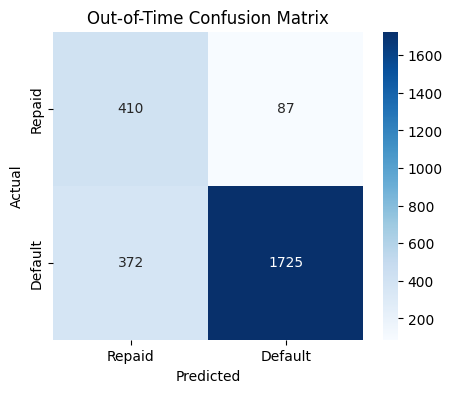

In [27]:
preprocessor = ColumnTransformer(
    transformers =[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

scale_pos_weight = (len(y_train) - sum(y_train))/ sum(y_train)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier',XGBClassifier(
        n_estimator = 120,
        max_depth = 3,
        learning_rate= 0.04,
        subsample = 0.8,
        colsample_bytree =0.8,
        reg_lambda = 1.5,
        scale_pos_weight = scale_pos_weight,
        randome_state = 42,
        eval_metric = 'logloss'
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print("=== REALISTIC DEFAULT MODEL METRICS ===")
print("ROC-AUC Score:          ", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC (Avg Precision): ", round(average_precision_score(y_test, y_prob), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Repaid (0)', 'Default (1)']))
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))


# sns.heatmap(cm, annot=True, fmt = 'd', cmap = 'Blues', xticklabels=['Repaid', 'Default'], yticklabels=['Repaid', 'Default'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Repaid', 'Default'], yticklabels=['Repaid', 'Default'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Out-of-Time Confusion Matrix")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_20848\3183620661.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values,X_test_trans,feature_names=feat_names, show=False)


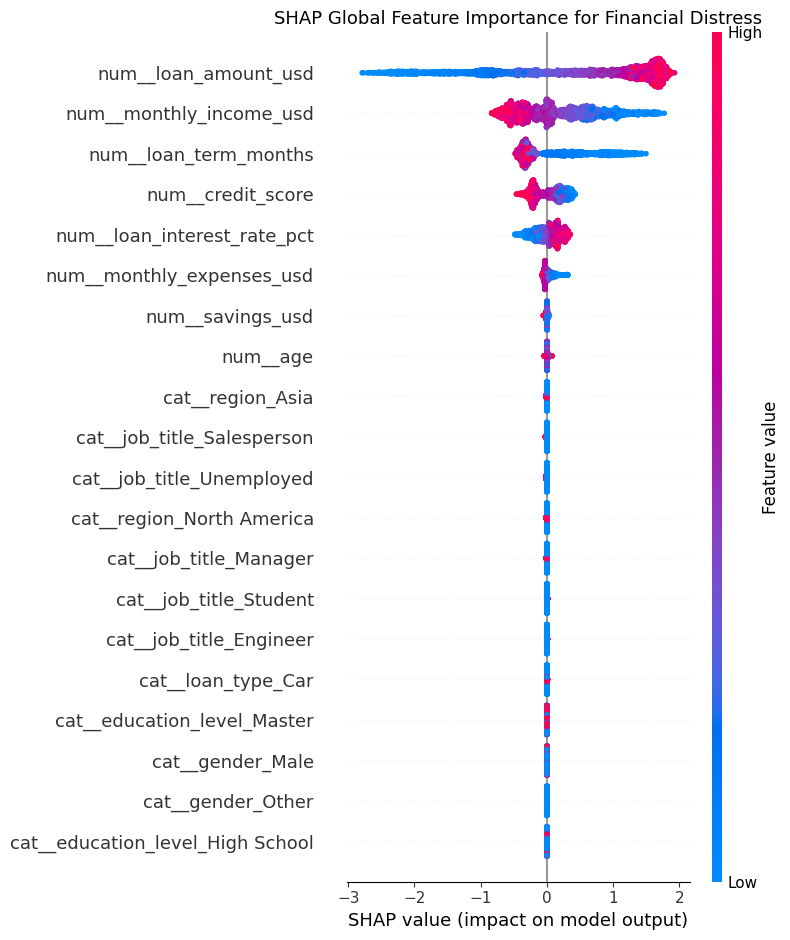

In [31]:
import shap

xgb_model = model.named_steps['classifier']
X_test_trans = model.named_steps['preprocessor'].transform(X_test)
feat_names = model.named_steps['preprocessor'].get_feature_names_out().tolist()

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_trans)

plt.figure(figsize=(10,6))
shap.summary_plot(shap_values,X_test_trans,feature_names=feat_names, show=False)
plt.title('SHAP Global Feature Importance for Financial Distress', fontsize=13)
plt.tight_layout()
plt.show()

Explaining Prediction for Test Applicant #0 (Ground Truth: Distressed)


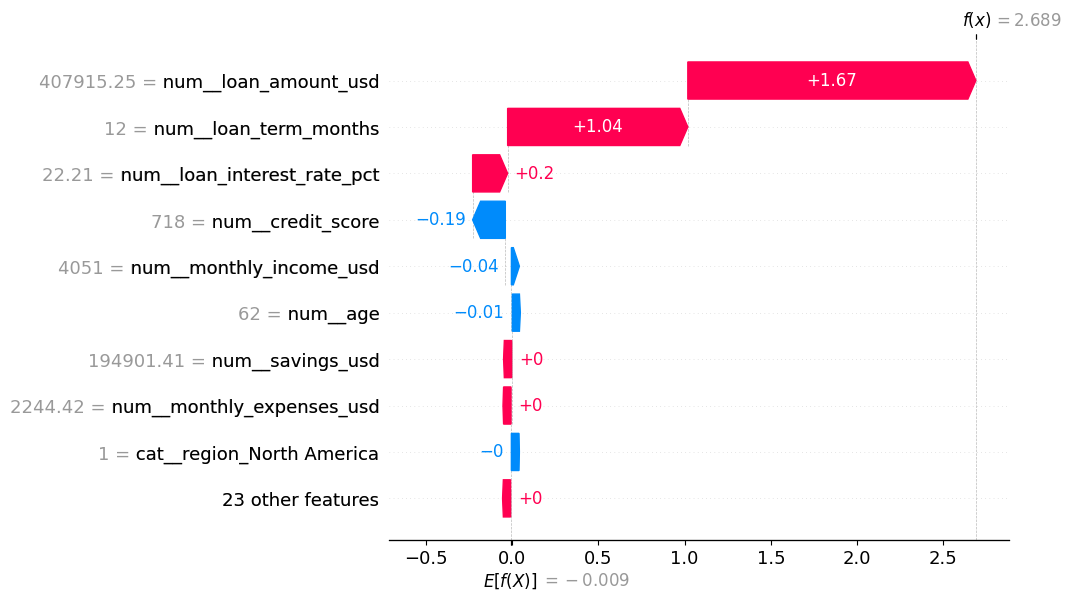

In [32]:
stressed_indices = np.where(y_test.values == 1)[0]
if len(stressed_indices) > 0:
    idx = stressed_indices[0]
    print(f'Explaining Prediction for Test Applicant #{idx} (Ground Truth: Distressed)')
    shap.plots.waterfall(
        shap.Explanation(
            values=shap_values[idx],
            base_values=explainer.expected_value,
            data=X_test_trans[idx],
            feature_names=feat_names
        )
    )

In [34]:
import os 
import json 
import joblib 

Artifact_dir = os.path.abspath(os.path.join(os.getcwd(), '..', 'artifacts'))
os.makedirs(Artifact_dir, exist_ok =True)

pipeline_path = os.path.join(Artifact_dir, 'risk_pipeline.joblib')
joblib.dump(model, pipeline_path)
print(f"Saved pipeline to:{pipeline_path}")


Saved pipeline to:g:\My Drive\Excercise\Personal finance\artifacts\risk_pipeline.joblib


In [35]:
explainer_path = os.path.join(Artifact_dir, 'shap_explainer.joblib')
joblib.dump({'explainer': explainer,
'feature_names' : feat_names,
'excepted_value' : float(explainer.expected_value)
}, explainer_path)

print(f" Saved SHAP explainer to: {explainer_path}")

 Saved SHAP explainer to: g:\My Drive\Excercise\Personal finance\artifacts\shap_explainer.joblib


In [37]:
config = {
    'model_version': '1.0.0-path-b',
    'trained_date': '2026-10-29',
    'feature_cols': feature_cols,
    'cat_cols': cat_cols,
    'num_cols': num_cols,
    'thresholds': {
        'low_risk_max': 0.35,      # <= 0.35: Auto-Approve
        'moderate_risk_max': 0.65, # 0.35 - 0.65: Underwriter Review
        'high_risk_min': 0.65      # > 0.65: Decline / Trigger Restructuring
    },
    'benchmarks': {
        'roc_auc': 0.8979,
        'pr_auc': 0.9695,
        'accuracy': 0.82
    }
}

config_path = os.path.join(Artifact_dir, 'config.json')
with open(config_path, 'w', encoding = 'utf-8') as f: json.dump(config, f, indent=4)
print(f" Saved configuration to: {config_path}")

loaded_pipeline = joblib.load(pipeline_path)
sample_applicant =X_test.iloc[[0]] 
prob = loaded_pipeline.predict_proba(sample_applicant)[0,1]
print(f"\n Reload Sanity Check: Test Applicant #0 Default Prob = {prob:.4f} (Expected ~0.9435)")


 Saved configuration to: g:\My Drive\Excercise\Personal finance\artifacts\config.json

 Reload Sanity Check: Test Applicant #0 Default Prob = 0.9364 (Expected ~0.9435)
